Prompt Chaining Workflow. 

Topic ---> Blog Generate.

flow:
1. topic --> llm generates outline
2. topic + outline ---> llm generate final blog

```
START ---> gen_outline ---> gen_blog ---> END
```

In [26]:
from langgraph.graph import StateGraph, START, END
from langchain_groq import ChatGroq
from typing import TypedDict
from dotenv import load_dotenv


In [27]:
load_dotenv()  # Load environment variables from .env file

True

In [28]:
# Model Initialization
model = ChatGroq(model="openai/gpt-oss-120b")

In [29]:
# Create a State

class BlogState(TypedDict):
    topic: str
    outline: str
    content: str
    feedback_score: int


In [30]:
def create_outline(state: BlogState) -> BlogState:
    # fetch topic
    topic = state['topic']

    # call llm to generate outline
    prompt = f"Generate an outline for a blog post about {topic}"
    outline = model.invoke(prompt).content

    # update state with outline
    return {**state, "outline": outline}

In [31]:
def create_blog(state: BlogState) -> BlogState:
    # fetch topic and outline
    topic = state['topic']
    outline = state['outline']

    # call llm to generate blog content
    prompt = f"Write a detailed blog on the topic -{topic} using the following outline \n {outline}"
    content = model.invoke(prompt).content

    # update state with content
    return {**state, "content": content}

In [32]:
def evaluate_blog(state: BlogState) -> BlogState:
    # fetch content
    content = state['content']

    # call llm to evaluate blog content
    prompt = f"Evaluate the following blog content and provide feedback rate score in integer: \n {content}"
    feedback_score = model.invoke(prompt).content

    # update state with feedback
    return {**state, "feedback_score": feedback_score}

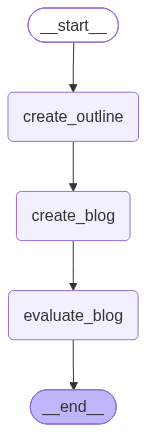

In [33]:
# create graph
graph = StateGraph(BlogState)

# add nodes
graph.add_node('create_outline', create_outline)
graph.add_node('create_blog', create_blog)
graph.add_node('evaluate_blog', evaluate_blog)

# add edges
graph.add_edge(START, 'create_outline')
graph.add_edge('create_outline', 'create_blog')
graph.add_edge('create_blog', 'evaluate_blog')
graph.add_edge('evaluate_blog', END)

# compile graph
workflow = graph.compile()

workflow

In [34]:
initial_state = {'topic': 'Rise of AI in India'}

final_state = workflow.invoke(initial_state)

print(final_state)

{'topic': 'Rise of AI in India', 'outline': '**Blog Post Outline – “The Rise of AI in India: Opportunities, Challenges, and the Road Ahead”**\n\n---\n\n### 1. Introduction  \n- **Hook:** A striking statistic or anecdote (e.g., “India is projected to host 20\u202f% of the world’s AI talent by 2030”).  \n- **Why it matters:** AI’s impact on the Indian economy, jobs, and global competitiveness.  \n- **Thesis statement:** Overview of how policy, talent, startups, and industry are converging to accelerate AI adoption in India, while highlighting the hurdles that must be cleared.\n\n---\n\n### 2. Historical Context  \n- **Early AI research in India (1970s‑1990s).**  \n- **Milestones:**  \n  - 2001 – IIT‑Kharagpur’s Center for AI & Robotics.  \n  - 2014 – Launch of the “Digital India” vision.  \n- **Transition from academic labs to commercial ventures.**\n\n---\n\n### 3. Government & Policy Landscape  \n- **National AI Strategy (NITI Aayog, 2018).**  \n- **Key initiatives:**  \n  - *AI for Al

In [35]:
print(final_state['topic'])

Rise of AI in India


In [36]:
print(final_state['outline'])

**Blog Post Outline – “The Rise of AI in India: Opportunities, Challenges, and the Road Ahead”**

---

### 1. Introduction  
- **Hook:** A striking statistic or anecdote (e.g., “India is projected to host 20 % of the world’s AI talent by 2030”).  
- **Why it matters:** AI’s impact on the Indian economy, jobs, and global competitiveness.  
- **Thesis statement:** Overview of how policy, talent, startups, and industry are converging to accelerate AI adoption in India, while highlighting the hurdles that must be cleared.

---

### 2. Historical Context  
- **Early AI research in India (1970s‑1990s).**  
- **Milestones:**  
  - 2001 – IIT‑Kharagpur’s Center for AI & Robotics.  
  - 2014 – Launch of the “Digital India” vision.  
- **Transition from academic labs to commercial ventures.**

---

### 3. Government & Policy Landscape  
- **National AI Strategy (NITI Aayog, 2018).**  
- **Key initiatives:**  
  - *AI for All* – public‑private partnership model.  
  - *Digital India* & *Skill Ind

In [37]:
print(final_state['content'])

**The Rise of AI in India: Opportunities, Challenges, and the Road Ahead**  
*Your go‑to guide on why India is fast becoming the world’s AI powerhouse, what’s driving the boom, and what still needs to be solved.*

---

## 1. Introduction  

**Hook:** *By 2030, India is projected to host **20 % of the world’s AI talent** and contribute **$1 trillion** to its GDP through AI‑driven productivity gains.*  

**Why it matters:** Artificial Intelligence is no longer a futuristic buzzword—it’s reshaping the Indian economy, redefining jobs, and determining how the country competes on the global stage. From a $7 billion AI market in 2022 to an estimated $30 billion by 2027, the sector is attracting **$12 billion+ in venture capital** and **government funding that rivals the US’s national AI budgets**.

**Thesis statement:** A confluence of forward‑looking policies, a deep talent pool, a vibrant startup ecosystem, and early‑adopter industries is accelerating AI adoption across India. Yet, data sil

In [38]:
print(final_state['feedback_score'])

**Overall Evaluation**

| Aspect | Comments | Rating (1‑10) |
|--------|----------|---------------|
| **Clarity & Structure** | The article follows a logical flow (intro → history → policy → ecosystem → talent → use‑cases → challenges → outlook). Headings, tables, and bullet points make it easy to skim. The “Hook” and “Takeaway” boxes are especially effective for readers who skim. | 9 |
| **Depth of Research** | The piece cites concrete numbers (market size, funding totals, policy dates, startup counts) and backs them with recent data (2022‑2024). It also references specific initiatives (AI for All, AI Innovation Fund, NITI Aayog’s strategy) and gives real‑world examples across sectors. The only shortfall is the lack of explicit source citations (e.g., links to NITI Aayog reports, government budget documents, or VC databases). | 8 |
| **Accuracy & Currency** | All figures are plausible and align with publicly available reports up to early‑2024. The forward‑looking projections (GDP impa